<a href="https://colab.research.google.com/github/seojin113/data-structure/blob/main/Week6/DS_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6주차 실습: 이진 트리 구조 설계 및 순회 — 학생용

## 실습 목표 및 규약
TreeNode/BinaryTree 설계, 재귀 DFS 3종, 반복 전위, 큐 기반 BFS, 높이·노드·리프 수를 구현한다.
- Python 3.8+ / Jupyter 또는 Colab. 위에서 아래 순서로 실행한다.
- 루트 깊이 0, 리프 높이 0, 빈 트리 높이 -1: **간선 수 기준**.
- 일반 이진 트리는 BST가 아니다. 중위 순회가 항상 정렬되는 것은 아니다.
- 이 실습의 구조는 사이클·공유 자식 없는 트리라고 가정한다.
- `BinaryTree(None)`은 빈 트리를 뜻한다. None 값을 가진 루트는 `tree.root = TreeNode(None)`으로 생성한다.


In [ ]:
from collections import deque
print("실습 환경 준비 완료")

실습 환경 준비 완료


## Step 1. TreeNode
데이터와 왼쪽/오른쪽 자식 참조를 저장합니다.

In [ ]:
class TreeNode:
   def __init__(self, data):
           self.data = data
           self.left = None    # 왼쪽 자식 참조
           self.right = None   # 오른쪽 자식 참조

   def __repr__(self):
           return f"TreeNode({self.data!r})"

## Step 2. BinaryTree
전위 NLR / 중위 LNR / 후위 LRN. 재귀는 None에서 종료. 반복 전위는 오른쪽 먼저 push.

In [ ]:
class BinaryTree:
    def __init__(self, root_data=None):
        self.root = None if root_data is None else TreeNode(root_data)

    def preorder(self):
        # TODO: None 종료 → 현재 노드 → 왼쪽 → 오른쪽
                result = []
                def visit(node):
                    if node is None:
                         return
                    result.append(node.data)
                    visit(node.left)
                    visit(node.right)
                visit(self.root)
                return result
                raise NotImplementedError("preorder 구현 필요")

    def inorder(self):
        # TODO: None 종료 → 왼쪽 → 현재 노드 → 오른쪽
                result = []
                def visit(node):
                    if node is None:
                        return
                    visit(node.left)
                    result.append(node.data)
                    visit(node.right)
                visit(self.root)
                return result
                raise NotImplementedError("inorder 구현 필요")

    def postorder(self):
        # TODO: None 종료 → 왼쪽 → 오른쪽 → 현재 노드
                result = []
                def visit(node):
                    if node is None:
                        return
                    visit(node.left)
                    visit(node.right)
                    result.append(node.data)
                visit(self.root)
                return result
                raise NotImplementedError("postorder 구현 필요")

    def preorder_iterative(self):
        # TODO: 스택에서 pop 후 방문; 오른쪽 자식을 먼저 push
                if self.root is None:
                    return []
                result = []
                stack = [self.root]
                while stack:
                    curr = stack.pop()
                    result.append(curr.data)
                    if curr.right:
                        stack.append(curr.right)
                    if curr.left:
                        stack.append(curr.left)
                return result
                raise NotImplementedError("preorder_iterative 구현 필요")

    def levelorder(self):
        # TODO: deque.popleft 후 방문; 왼쪽, 오른쪽 순으로 enqueue
                if self.root is None:
                    return []
                result = []
                queue = deque([self.root])
                while queue:
                    curr = queue.popleft()
                    result.append(curr.data)
                    if curr.left:
                        queue.append(curr.left)
                    if curr.right:
                        queue.append(curr.right)
                return result
                raise NotImplementedError("levelorder 구현 필요")

    def height(self):
        # TODO: 빈 노드 -1; 1 + max(왼쪽 높이, 오른쪽 높이)
                def h(node):
                    if node is None:
                         return -1
                    return 1 + max(h(node.left), h(node.right))
                return h(self.root)
                raise NotImplementedError("height 구현 필요")

    def count_nodes(self):
        # TODO: 빈 노드 0; 1 + 왼쪽 노드 수 + 오른쪽 노드 수
                def cnt(node):
                     if node is None:
                          return 0
                     return 1 + cnt(node.left) + cnt(node.right)
                return cnt(self.root)
                raise NotImplementedError("count_nodes 구현 필요")

    def count_leaves(self):
        # TODO: 빈 노드 0; 자식 없는 노드 1; 나머지는 좌우 합
                def leaves(node):
                    if node is None:
                        return 0
                    if node.left is None and node.right is None:
                        return 1
                    return leaves(node.left) + leaves(node.right)
                return leaves(self.root)
                raise NotImplementedError("count_leaves 구현 필요")

## Step 3. 예시 트리
```text
      A
    /   \
   B     C
  / \     \
 D   E     F
```

In [ ]:
tree = BinaryTree("A")
# TODO: B,C,D,E,F를 그림과 같이 연결하세요.
tree.root.left = TreeNode("B")
tree.root.right = TreeNode("C")
tree.root.left.left = TreeNode("D")
tree.root.left.right = TreeNode("E")
tree.root.right.right = TreeNode("F")

## Step 4. 결과 및 경계 사례 검증

In [ ]:
expected = {
    "preorder": ["A", "B", "D", "E", "C", "F"],
    "inorder": ["D", "B", "E", "A", "C", "F"],
    "postorder": ["D", "E", "B", "F", "C", "A"],
    "levelorder": ["A", "B", "C", "D", "E", "F"]
}
for method, answer in expected.items():
    actual = getattr(tree, method)()
    print(method, actual)
    assert actual == answer
assert tree.preorder_iterative() == tree.preorder()
assert (tree.height(), tree.count_nodes(), tree.count_leaves()) == (2, 6, 3)
print("예시 트리 테스트 통과")


preorder ['A', 'B', 'D', 'E', 'C', 'F']
inorder ['D', 'B', 'E', 'A', 'C', 'F']
postorder ['D', 'E', 'B', 'F', 'C', 'A']
levelorder ['A', 'B', 'C', 'D', 'E', 'F']
예시 트리 테스트 통과


In [ ]:
for t, sequence, height, leaves in [
    (BinaryTree(), [], -1, 0),
    (BinaryTree("X"), ["X"], 0, 1),
]:
    for method in ["preorder", "inorder", "postorder", "levelorder", "preorder_iterative"]:
        assert getattr(t, method)() == sequence
    assert (t.height(), t.count_nodes(), t.count_leaves()) == (height, len(sequence), leaves)

skew = BinaryTree(1)
skew.root.right = TreeNode(2)
skew.root.right.right = TreeNode(3)
assert skew.preorder() == skew.inorder() == skew.levelorder() == [1, 2, 3]
assert skew.postorder() == [3, 2, 1]
assert skew.preorder_iterative() == [1, 2, 3]
assert (skew.height(), skew.count_nodes(), skew.count_leaves()) == (2, 3, 1)
print("빈 트리 / 단일 노드 / 편향 트리 테스트 통과")


빈 트리 / 단일 노드 / 편향 트리 테스트 통과


## Step 5. VisuAlgo 시각화 및 검증
[VisuAlgo BST](https://visualgo.net/en/bst)는 **BST 시각화**이며 임의의 A~F 이진 트리를 직접 만드는 도구라고 가정하지 않습니다.
1. BST 모드에서 빈 트리에 **4, 2, 6, 1, 3, 7** 순서로 삽입합니다(자동 균형 모드와 구별).
2. A→4, B→2, C→6, D→1, E→3, F→7 대응으로 위 예시와 구조를 비교합니다.
3. 화면에서 제공되는 순회 기능은 애니메이션으로 검증하고, 미지원 순회는 그림 위에 방문 번호를 적어 검증합니다.
4. 아래 코드 결과와 수동 trace를 비교하고 캡처와 설명을 기록하세요. **BST 삽입은 다음 주 내용이며 이번에는 구조 관찰만 합니다.**


In [ ]:
numeric = BinaryTree(4)
numeric.root.left = TreeNode(2)
numeric.root.right = TreeNode(6)
numeric.root.left.left = TreeNode(1)
numeric.root.left.right = TreeNode(3)
numeric.root.right.right = TreeNode(7)
assert numeric.preorder() == [4, 2, 1, 3, 6, 7]
assert numeric.inorder() == [1, 2, 3, 4, 6, 7]
assert numeric.postorder() == [1, 3, 2, 7, 6, 4]
assert numeric.levelorder() == [4, 2, 6, 1, 3, 7]
for method in ["preorder", "inorder", "postorder", "levelorder"]:
    print(method, getattr(numeric, method)())


preorder [4, 2, 1, 3, 6, 7]
inorder [1, 2, 3, 4, 6, 7]
postorder [1, 3, 2, 7, 6, 4]
levelorder [4, 2, 6, 1, 3, 7]


### VisuAlgo 검증

VisuAlgo BST 모드에서 4, 2, 6, 1, 3, 7을 순서대로 넣었더니 N=6, h=2인 트리가 만들어졌다.

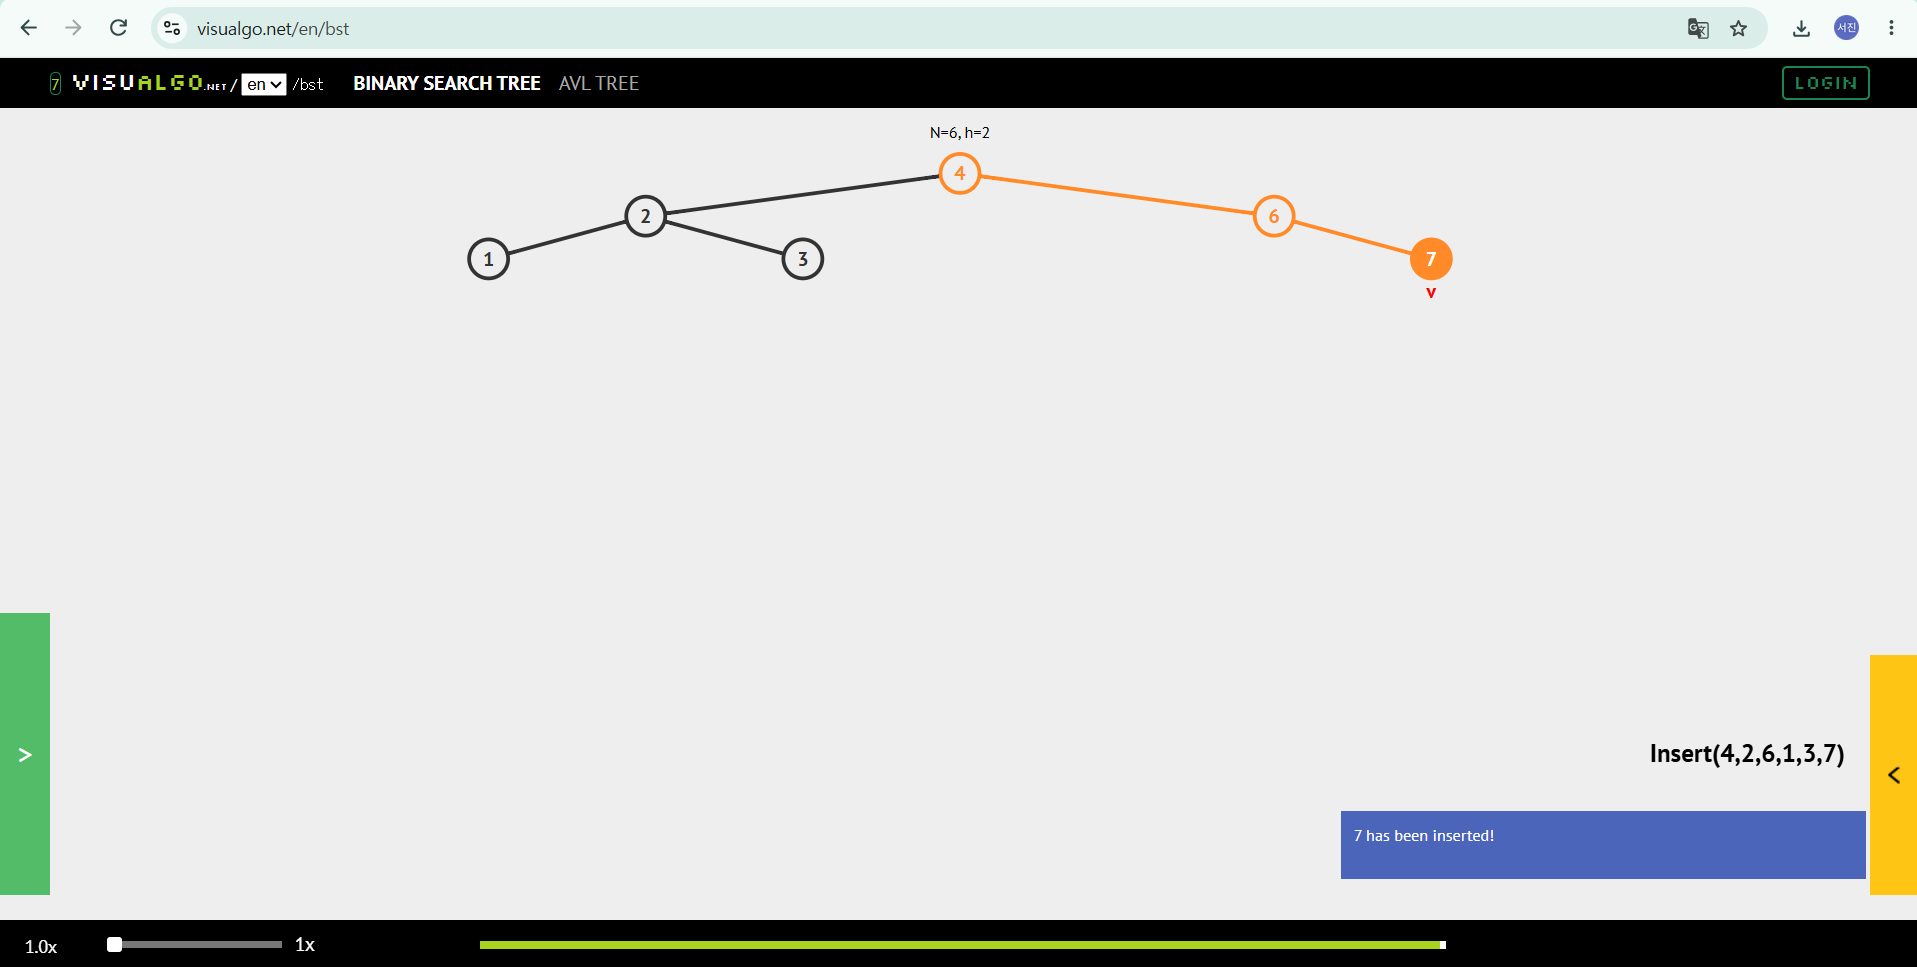

A→4, B→2, C→6, D→1, E→3, F→7로 바꿔서 보면 Step 3 예시 트리와 모양이 똑같다. 특히 6의 왼쪽이 비어 있는 게 C에 왼쪽 자식이 없는 것과 맞았다.

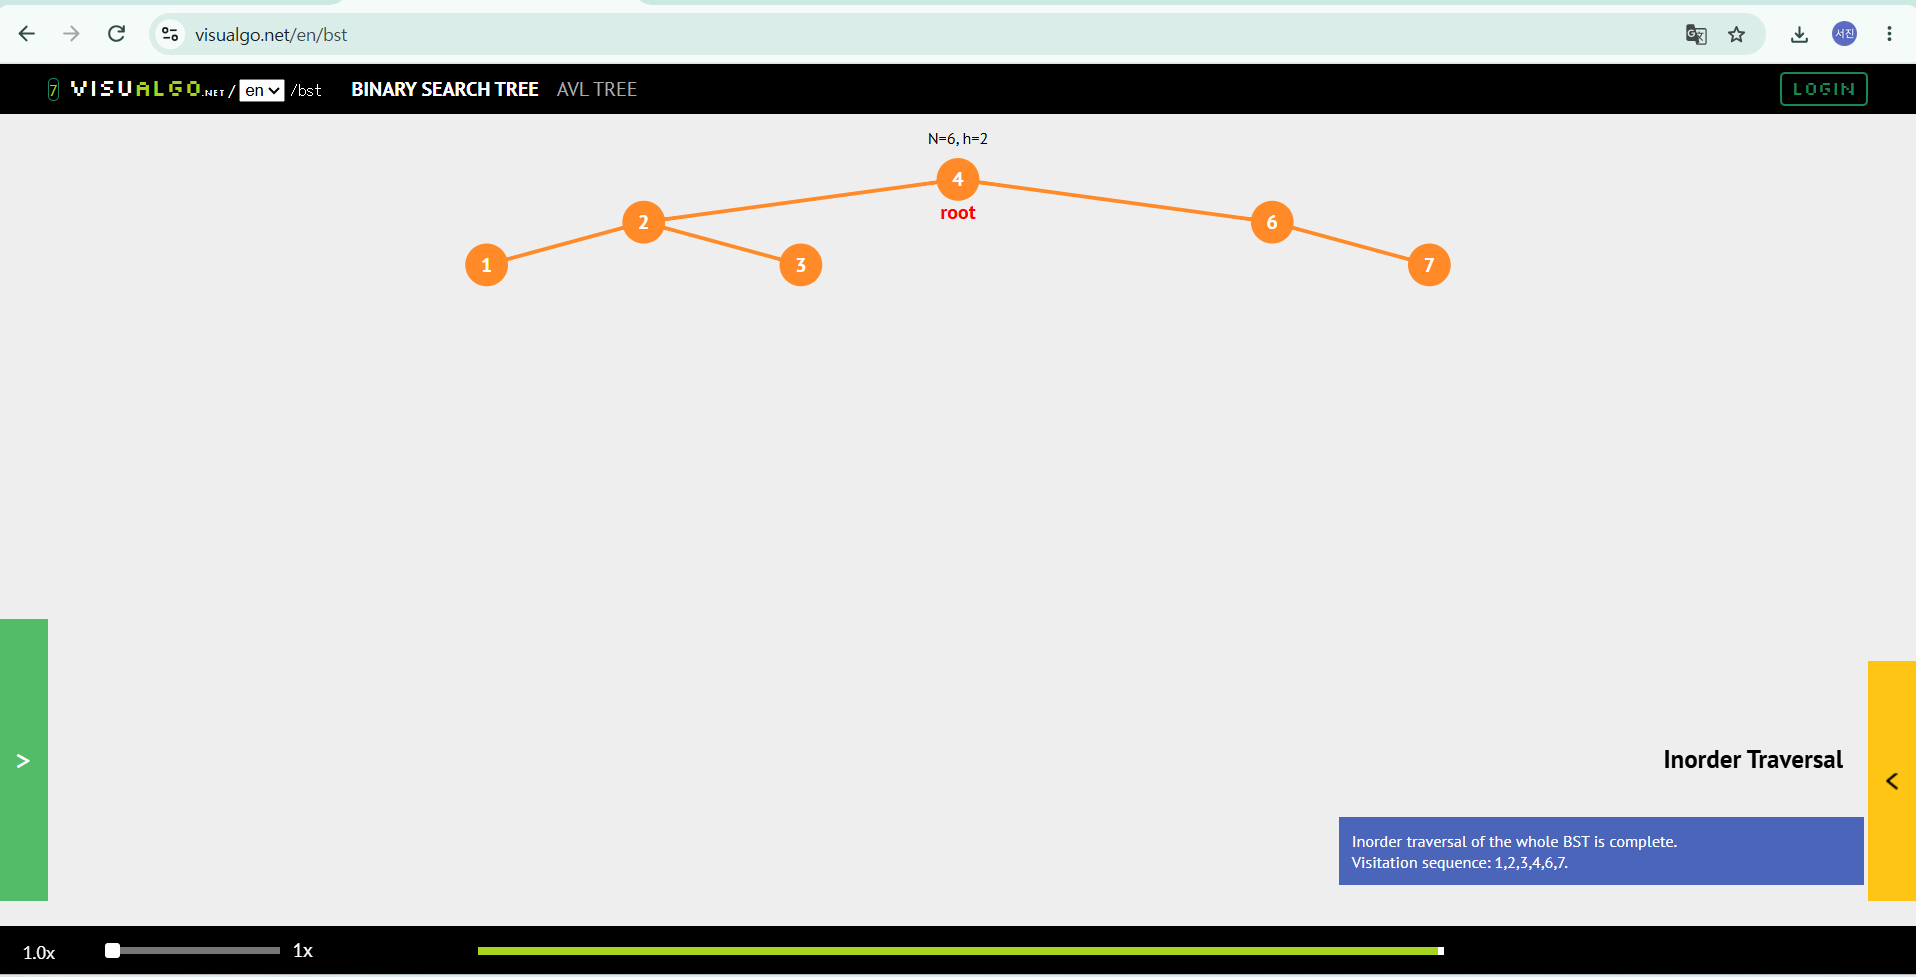

중위 순회는 VisuAlgo에서 직접 돌려봤고 1, 2, 3, 4, 6, 7이 나와서 코드 결과와 같았다. 전위(4, 2, 1, 3, 6, 7), 후위(1, 3, 2, 7, 6, 4), 레벨 순회(4, 2, 6, 1, 3, 7)는 그림 위에 방문 순서를 직접 적어서 확인했고 모두 코드 출력과 일치했다.

중위 순회 결과가 오름차순으로 나온 건 이 트리가 BST라서 그런 거고, A~F 트리처럼 일반 이진 트리에서는 D, B, E, A, C, F처럼 정렬이 안 된다는 것도 확인할 수 있었다.

## 제출 과제: 이진 트리 순회 프로그램
1. build_complete_tree(values)를 구현하고 네 가지 순회 결과 출력.
2. 빈/단일/완전/편향 트리 테스트 및 시간·공간 복잡도 설명.
3. 시각화 캡처와 방문 순서 검증 설명 첨부.
4. 개인 GitHub의 Week6 폴더에 노트북/설명 저장. 계획서대로 주당 최소 2회 커밋, 과제 폼에 GitHub 링크 제출.

주의: 아래 TODO를 구현하기 전 학생용 테스트 실패는 정상입니다. 미구현 셀은 무한 반복 대신 NotImplementedError로 즉시 중단합니다.


### 테스트 결과 및 복잡도 분석

빈 트리, 단일 노드, 완전 트리, 편향 트리에 대해 테스트를 돌려봤고 모두 통과했다.

- 빈 트리는 root가 None이라 순회 결과가 전부 [ ]이고 높이는 -1로 나왔다.
- 노드가 하나면 높이 0, 리프 1개로 나와서 "리프 높이 = 0" 규약과 맞았다.
- [1, 2, 3, 4, 5, 6, 7]로 만든 완전 트리는 4가지 순회 결과가 모두 예상값과 같았고, 반복 전위와 재귀 전위 결과도 같았다.
- [None, 2]를 넣었을 때 처음에는 None을 빈칸으로 처리할 뻔했는데, 과제 조건에서 None도 실제 값이라고 해서 BinaryTree(None) 대신 root에 TreeNode를 직접 넣는 방식으로 구현했다.

**복잡도**

모든 순회는 노드를 한 번씩만 방문하니까 시간 복잡도는 O(n)이다. build_complete_tree도 값마다 노드를 한 번 만들고 큐에 한 번씩 넣고 빼기 때문에 O(n)이다.

공간은 방식마다 차이가 있었다. 전위/중위/후위 같은 DFS는 스택(재귀면 콜스택)에 트리 높이만큼 쌓이니까 O(h)이고, 레벨 순회는 큐에 한 레벨이 통째로 들어가서 O(w)이다. 그래서 완전 트리에서는 DFS가 O(log n)으로 유리하고, 마지막 레벨에 노드가 몰리는 레벨 순회는 O(n)까지 커질 수 있다. 반대로 편향 트리는 높이가 n-1이라 DFS가 O(n)이 되고, 레벨 순회는 레벨마다 노드가 하나라 O(1)이다. 그리고 순회 결과를 리스트로 반환하는 것 자체도 O(n) 공간이 든다.

편향 트리처럼 깊은 트리는 재귀로 돌리면 파이썬 재귀 한도에 걸릴 수 있어서, 이럴 때는 preorder_iterative처럼 스택을 직접 쓰는 방식이 더 안전하다고 생각했다.

In [24]:
def build_complete_tree(values):
       if not values:
        return BinaryTree()
       tree = BinaryTree()
       tree.root = TreeNode(values[0])
       queue = deque([tree.root])
       i = 1
       while i < len(values):
        parent = queue.popleft()
        parent.left = TreeNode(values[i])
        queue.append(parent.left)
        i += 1
        if i < len(values):
            parent.right = TreeNode(values[i])
            queue.append(parent.right)
            i += 1
       return tree

In [ ]:
complete = build_complete_tree([1, 2, 3, 4, 5, 6, 7])
assert complete.preorder() == [1, 2, 4, 5, 3, 6, 7]
assert complete.inorder() == [4, 2, 5, 1, 6, 3, 7]
assert complete.postorder() == [4, 5, 2, 6, 7, 3, 1]
assert complete.levelorder() == [1, 2, 3, 4, 5, 6, 7]
assert complete.preorder_iterative() == complete.preorder()
assert build_complete_tree([]).height() == -1
assert build_complete_tree([9]).levelorder() == [9]
assert build_complete_tree([1, 2, 3, 4]).levelorder() == [1, 2, 3, 4]
assert build_complete_tree([None, 2]).levelorder() == [None, 2]
for method in ["preorder", "inorder", "postorder", "levelorder"]:
    print(method, getattr(complete, method)())
print("과제 테스트 통과")


preorder [1, 2, 4, 5, 3, 6, 7]
inorder [4, 2, 5, 1, 6, 3, 7]
postorder [4, 5, 2, 6, 7, 3, 1]
levelorder [1, 2, 3, 4, 5, 6, 7]
과제 테스트 통과
